In [ ]:
!pip install groq

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 138.3/138.3 kB 7.0 MB/s eta 0:00:00


In [ ]:
import os

os.environ["GROQ_API_KEY"] = "ENTER YOUR API KEY"


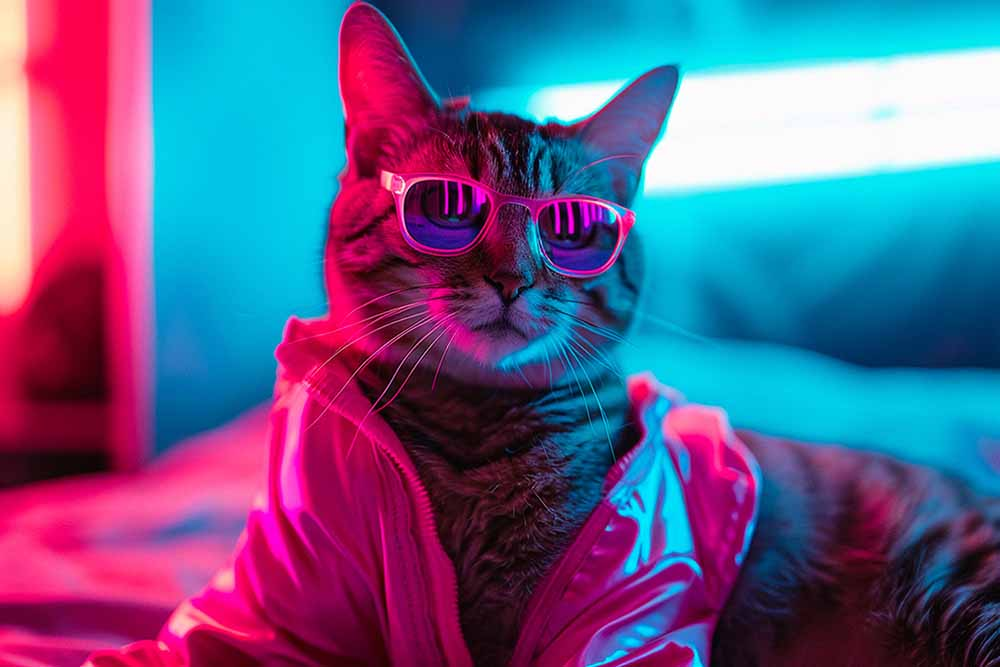

In [ ]:
from PIL import Image
import requests
from io import BytesIO

image_url = "https://www.mamp.one/wp-content/uploads/2024/09/image-resources2.jpg"

response = requests.get(image_url, stream=True)
image = Image.open(response.raw).convert("RGB")

image


In [ ]:
from transformers import BlipProcessor, BlipForConditionalGeneration
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"

processor = BlipProcessor.from_pretrained(
    "Salesforce/blip-image-captioning-base"
)

model = BlipForConditionalGeneration.from_pretrained(
    "Salesforce/blip-image-captioning-base"
).to(device)

inputs = processor(image, return_tensors="pt").to(device)

with torch.no_grad():
    output = model.generate(**inputs)

caption = processor.decode(output[0], skip_special_tokens=True)

print("Generated Caption:")
print(caption)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

The image processor of type `BlipImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

...

pytorch_model.bin:   0%|          | 0.00/990M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/990M [00:00<?, ?B/s]

The tied weights mapping and config for this model specifies to tie text_decoder.cls.predictions.bias to text_decoder.cls.predictions.decoder.bias, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie text_decoder.bert.embeddings.word_embeddings.weight to text_decoder.cls.predictions.decoder.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
BlipForConditionalGeneration LOAD REPORT from: Salesforce/blip-image-captioning-base
Key                                       | Status     |  | 
------------------------------------------+------------+--+-
text_decoder.bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identic

Generated Caption:
a cat wearing sunglasses and a pink jacket


In [ ]:
from groq import Groq

client = Groq()
question = "What animal is in the image?"


In [ ]:
system_prompt = """
You are a visual reasoning controller for a Vision Transformer.

Your job is to decide which VISUAL properties of the image are important
to answer the question.

STRICT RULES:
- Output ONLY valid JSON.
- No explanations.
- No markdown.
- No text outside JSON.
- Use short, concrete, observable visual concepts.
- Include distinctive attributes (clothing, color, accessories).
- Do NOT ignore important visible objects.
- "visual_focus" must contain multiple relevant attributes if present.
- "ignore" should only include clearly irrelevant background elements.
- "knowledge" should contain concise factual knowledge relevant to answering.
- Knowledge must explain why the visual attributes matter for answering.
- Avoid trivial statements.

Return JSON in EXACT format:

{
  "visual_focus": [],
  "ignore": [],
  "knowledge": []
}
"""

user_prompt = f"""
Question:
{question}

Image caption:
{caption}

Identify:
1. The main object(s)
2. Important visible attributes
3. Any distinctive or unusual elements
4. Relevant knowledge needed to answer the question

Return ONLY JSON.
"""



In [ ]:
completion = client.chat.completions.create(
    model="llama-3.3-70b-versatile",
    messages=[
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": user_prompt}
    ],
    temperature=0.2,
    response_format={"type": "json_object"}
)

llm_output = completion.choices[0].message.content
print(llm_output)


{
  "visual_focus": [
      "cat",
      "sunglasses",
      "pink jacket"
   ],
   "ignore": [],
   "knowledge": [
      "cats are a species of animal",
      "sunglasses and jackets are unusual accessories for animals"
   ]
}


In [ ]:
type(llm_output)

dict

In [ ]:
import json
llm_output = json.loads(llm_output)

In [ ]:
import torch
from transformers import CLIPTokenizer, CLIPTextModel

device = "cuda" if torch.cuda.is_available() else "cpu"

tokenizer = CLIPTokenizer.from_pretrained("openai/clip-vit-base-patch16")    # we are using clip model for text encoding since this model is aligned to visual space aswell
text_encoder = CLIPTextModel.from_pretrained("openai/clip-vit-base-patch16").to(device)

text_encoder.eval()


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: openai/clip-vit-base-patch16
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
vision_model.encoder.layers.{0...11}.self_attn.out_proj.weight | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.q_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.

CLIPTextModel(
  (text_model): CLIPTextTransformer(
    (embeddings): CLIPTextEmbeddings(
      (token_embedding): Embedding(49408, 512)
      (position_embedding): Embedding(77, 512)
    )
    (encoder): CLIPEncoder(
      (layers): ModuleList(
        (0-11): 12 x CLIPEncoderLayer(
          (self_attn): CLIPAttention(
            (k_proj): Linear(in_features=512, out_features=512, bias=True)
            (v_proj): Linear(in_features=512, out_features=512, bias=True)
            (q_proj): Linear(in_features=512, out_features=512, bias=True)
            (out_proj): Linear(in_features=512, out_features=512, bias=True)
          )
          (layer_norm1): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
          (mlp): CLIPMLP(
            (activation_fn): QuickGELUActivation()
            (fc1): Linear(in_features=512, out_features=2048, bias=True)
            (fc2): Linear(in_features=2048, out_features=512, bias=True)
          )
          (layer_norm2): LayerNorm((512,), eps=1e

In [ ]:
visual_focus = llm_output.get("visual_focus", [])
knowledge = llm_output.get("knowledge", [])
visual_focus,'\n',knowledge

(['cat', 'sunglasses', 'pink jacket'],
 '\n',
 ['cats are a species of animal',
  'sunglasses and jackets are unusual accessories for animals'])

In [ ]:
def create_guidance_vector(visual_focus, knowledge,
                           visual_weight=2.0,
                           knowledge_weight=1.0):

    all_text = visual_focus + knowledge

    if len(all_text) == 0:
        raise ValueError("No text available to create guidance vector.")

    inputs = tokenizer(
        all_text,
        padding=True,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        outputs = text_encoder(**inputs)

    embeddings = outputs.last_hidden_state.mean(dim=1)  # [N, 512]

    num_visual = len(visual_focus)

    if num_visual > 0:
        visual_embeds = embeddings[:num_visual]
        visual_mean = visual_embeds.mean(dim=0) * visual_weight
    else:
        visual_mean = torch.zeros(embeddings.shape[1]).to(device)

    if len(knowledge) > 0:
        knowledge_embeds = embeddings[num_visual:]
        knowledge_mean = knowledge_embeds.mean(dim=0) * knowledge_weight
    else:
        knowledge_mean = torch.zeros(embeddings.shape[1]).to(device)

    total_weight = 0
    if num_visual > 0:
        total_weight += visual_weight
    if len(knowledge) > 0:
        total_weight += knowledge_weight

    P_raw = (visual_mean + knowledge_mean) / total_weight

    return P_raw


In [ ]:
P_raw = create_guidance_vector(visual_focus, knowledge)

print("Guidance vector shape:", P_raw.shape)


Guidance vector shape: torch.Size([512])


In [ ]:
P_raw[:10]

tensor([ 0.0145, -0.0742,  0.3132, -0.1649, -1.2068, -0.3920,  0.1026, -0.3524,
        -1.3000,  0.2625], device='cuda:0')

In [ ]:
from transformers import ViTModel
vit = ViTModel.from_pretrained("google/vit-base-patch16-224") # this is a ViT model only deal with images and outputs image embedding


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key                 | Status     | 
--------------------+------------+-
classifier.weight   | UNEXPECTED | 
classifier.bias     | UNEXPECTED | 
pooler.dense.bias   | MISSING    | 
pooler.dense.weight | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
vit.config.hidden_size


768

In [ ]:
# 512 ----> 768 ----> attention

google/vit-base-patch16-224, openai/clip-vit-base-patch16
are these same we did text encoding of json using openai/clip-vit-base-patch16
but now you are using other one

Very good question 👏 — this is exactly the kind of confusion that must be cleared before we go further.

Short answer:

❌ They are NOT the same model.
✅ That is intentional.
⚠️ But we must understand the implications.

Let’s break this properly.

🔎 The Two Models You Are Using
1️⃣ openai/clip-vit-base-patch16

This model contains:

CLIP image encoder

CLIP text encoder

You are using ONLY:

CLIPTextModel


Its text embedding dimension:

512


It lives in a vision-language aligned space.

2️⃣ google/vit-base-patch16-224

This is:

A pure Vision Transformer

Trained on ImageNet

Image-only model

Hidden size:

768


It has:

No text encoder

No alignment with CLIP text space

🚨 Important Insight

Right now you are combining:

CLIP text space  →  ViT image space


These were trained independently.

So their internal representations are different.

🤔 Is That Wrong?

No.
But it means:

You MUST learn a projection layer.

Which we are already doing.

That projection layer learns:

“How do CLIP semantic directions correspond to ViT feature channels?”

🧠 But There Is a Cleaner Option

Instead of using:

google/vit-base-patch16-224


You could use:

openai/clip-vit-base-patch16


And use its image encoder instead.

Then:

Text encoder and image encoder share same training space

Alignment is naturally stronger

Projection might even be simplified

In [ ]:
from transformers import ViTModel

vit = ViTModel.from_pretrained("google/vit-base-patch16-224")

hidden_size = vit.config.hidden_size
print("ViT hidden size:", hidden_size)


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key                 | Status     | 
--------------------+------------+-
classifier.weight   | UNEXPECTED | 
classifier.bias     | UNEXPECTED | 
pooler.dense.bias   | MISSING    | 
pooler.dense.weight | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


ViT hidden size: 768


In [ ]:
import torch.nn as nn

projection_layer = nn.Linear(512, hidden_size)
projection_layer = projection_layer.to(device)

print(projection_layer)


Linear(in_features=512, out_features=768, bias=True)


In [ ]:
P_projected = projection_layer(P_raw)

print("Projected shape:", P_projected.shape)


Projected shape: torch.Size([768])


In [ ]:
P_projected = P_projected.unsqueeze(0)

print("Final shape for attention:", P_projected.shape)


Final shape for attention: torch.Size([1, 768])


In [ ]:
print("Raw embedding:", P_raw.shape)
print("Projected embedding:", P_projected.shape)
print("ViT hidden size:", hidden_size)


Raw embedding: torch.Size([512])
Projected embedding: torch.Size([1, 768])
ViT hidden size: 768
